<a href="https://colab.research.google.com/github/vatsalmalkari/LoRA-finetuning-project/blob/main/notebooks/experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LoRA replication on Gemma 3 1B: baseball QA

Runs every experiment for the MSDS 534 project: base model (zero-shot and few-shot), LoRA, QLoRA,
full fine-tuning, then the rank and module comparisons from the paper (Tables 5 and 6).

**Before you start**
1. *Runtime → Change runtime type → **L4 GPU*** (use A100 only if full fine-tuning runs out of memory, and then rerun everything on A100 so numbers are comparable).
2. Colab *Secrets* (key icon, left sidebar): add `HF_TOKEN` (a Hugging Face read token from an account that has accepted the Gemma terms). If the GitHub repo is private, also add `GITHUB_TOKEN`.
3. Run top to bottom. Results are written to Google Drive, and finished runs are **skipped** on rerun, so a disconnect never loses work: reconnect and run all again.

The code lives in `src/lora_exp.py` (training, evaluation, measurement) and `src/scoring.py` (answer scoring).

## 0. Setup

In [30]:
REPO_URL = "https://github.com/vatsalmalkari/LoRA-finetuning-project.git"
REPO_DIR = "/content/LoRA-finetuning-project"
DRIVE_DIR = "/content/drive/MyDrive/lora_project"   # results persist here

import os
from google.colab import drive, userdata
drive.mount("/content/drive")

def secret(name):
    try:
        return userdata.get(name)
    except Exception:
        return None

if not os.path.exists(REPO_DIR):
    gh = secret("GITHUB_TOKEN")
    url = REPO_URL.replace("https://", f"https://{gh}@") if gh else REPO_URL
    !git clone -q {url} {REPO_DIR}
else:
    !git -C {REPO_DIR} pull -q
%cd {REPO_DIR}
!git log --oneline -1

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/LoRA-finetuning-project
9748a38 (HEAD -> main, origin/main, origin/HEAD) Subspace similarity on the learned output side; unambiguous figure labels


In [31]:
!pip install -q -U transformers peft accelerate bitsandbytes

In [32]:
import sys, json, torch
sys.path.insert(0, "src")
import importlib, lora_exp, scoring
import analysis
importlib.reload(scoring); importlib.reload(lora_exp); importlib.reload(analysis)
from lora_exp import RunConfig, run, load_jsonl, check_frozen_test, summarize, mcnemar, load_results

from huggingface_hub import login
login(secret("HF_TOKEN"))

import transformers, peft
print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__)
gpu = torch.cuda.get_device_name(0)
mem = torch.cuda.get_device_properties(0).total_memory / 2**30
# is_bf16_supported() is True even on T4 (emulated, slow); real bf16 needs compute capability 8.0+
PRECISION = "bf16" if torch.cuda.get_device_capability(0)[0] >= 8 else "fp32"
print(f"GPU: {gpu} ({mem:.1f} GB)   precision: {PRECISION}")
if "T4" in gpu:
    print("WARNING: T4 has no fast bf16 and Gemma 3 can overflow in fp16; using fp32. "
          "Use the T4 only for the memory demo in section 8.")

torch 2.14.1+cu130 | transformers 5.24.1 | peft 0.22.0
GPU: NVIDIA L4 (22.0 GB)   precision: bf16


## 1. Data

`USE_UNVERIFIED = True` reads the pipeline-check split built before the rules questions were verified.
It is fine for section 2 but **never report numbers from it**. Once the team has verified
`data/raw/rules_mc.json` and run `python src/build_dataset.py`, commit `data/processed/`, push, and set this to `False`.

In [33]:
USE_UNVERIFIED = False   # real, frozen split (rules verified 2026-11-24)

DATA_DIR = "data/processed/unverified" if USE_UNVERIFIED else "data/processed"
data = {s: load_jsonl(f"{DATA_DIR}/{s}.jsonl") for s in ["train", "val", "test"]}
if not USE_UNVERIFIED:
    print("frozen test set OK:", check_frozen_test(DATA_DIR)[:16])
RESULTS = f"{DRIVE_DIR}/{'results_unverified' if USE_UNVERIFIED else 'results'}"
print({s: len(v) for s, v in data.items()}, "->", RESULTS)
print(data["train"][0]["messages"])

frozen test set OK: e70493c943c10394
{'train': 300, 'val': 30, 'test': 100} -> /content/drive/MyDrive/lora_project/results
[{'content': "Which runs count toward a pitcher's earned run average?\nA) All runs allowed\nB) Earned runs only, as determined by the official scorer under the earned-run rules\nC) Only runs that score on hits\nD) Only runs scored on home runs\nAnswer with the letter only.", 'role': 'user'}, {'content': 'B', 'role': 'assistant'}]


### Model shapes (for the report's math section)

LoRA on a weight $W_0 \in \mathbb{R}^{d_{out} \times d_{in}}$ adds $r(d_{in} + d_{out})$ parameters.
The paper's count $2 \hat L d_{model} r$ assumes square $W_q, W_v$; Gemma 3 uses grouped-query attention, so they are not square.

In [34]:
from transformers import AutoConfig
c = AutoConfig.from_pretrained(lora_exp.MODEL_ID)
c = getattr(c, "text_config", c)
d, L = c.hidden_size, c.num_hidden_layers
hd = getattr(c, "head_dim", d // c.num_attention_heads)
shapes = {"q_proj": (d, c.num_attention_heads * hd), "k_proj": (d, c.num_key_value_heads * hd),
          "v_proj": (d, c.num_key_value_heads * hd), "o_proj": (c.num_attention_heads * hd, d)}
print(f"d_model={d}  layers={L}  heads={c.num_attention_heads}  kv_heads={c.num_key_value_heads}  head_dim={hd}")
for k, (i, o) in shapes.items():
    print(f"  {k}: {i} -> {o}   LoRA params per layer per unit rank: {i + o}")
for targets, r in [(("q_proj", "v_proj"), 8), (("q_proj",), 8), (("q_proj", "v_proj"), 4),
                   (("q_proj", "k_proj", "v_proj", "o_proj"), 2)]:
    n = L * r * sum(sum(shapes[t]) for t in targets)
    print(f"  r={r} on {'+'.join(targets)}: {n:,} trainable params")

d_model=1152  layers=26  heads=4  kv_heads=1  head_dim=256
  q_proj: 1152 -> 1024   LoRA params per layer per unit rank: 2176
  k_proj: 1152 -> 256   LoRA params per layer per unit rank: 1408
  v_proj: 1152 -> 256   LoRA params per layer per unit rank: 1408
  o_proj: 1024 -> 1152   LoRA params per layer per unit rank: 2176
  r=8 on q_proj+v_proj: 745,472 trainable params
  r=8 on q_proj: 452,608 trainable params
  r=4 on q_proj+v_proj: 372,736 trainable params
  r=2 on q_proj+k_proj+v_proj+o_proj: 372,736 trainable params


## 2. Pipeline check

LoRA on 20 training examples for one epoch, scored on the validation set. Confirm that the loss goes down,
nothing is NaN, and the responses look like answers. Written to a separate folder, never reported.

In [ ]:
chk = run(RunConfig("lora", n_train=20, epochs=1, batch_size=4, precision=PRECISION),
          data, f"{DRIVE_DIR}/pipeline_check", eval_split="val", latency=False, save_adapter=False,
          overwrite=True)
print("losses:", [round(x, 3) for x in chk["train"]["losses"]])
print(f"peak memory {chk['peak_train_mem_gb']:.2f} GB, {chk['train']['tokens_per_second']:.0f} tok/s")
preds = json.load(open(f"{DRIVE_DIR}/pipeline_check/{chk['name']}.predictions.json"))["zero_shot"]
for p in preds[:8]:
    print(f"[{p['qtype']}] gold={p['answer']!r:22} got={p['response'][:60]!r}  strict={p['strict']}")

=== lora_r8_q-v_lr0.0002_s1_n20__val ===


tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported. torchao support in PEFT is disabled; if you want to use a torchao-quantized model with PEFT, please upgrade torchao.
  warnings.warn(


  trainable 745,472 / 1,000,631,424 (0.0746%)
  step    1/5  epoch 1  loss 4.9805  lr 2.00e-04
  step    5/5  epoch 1  loss 3.2222  lr 0.00e+00
  accuracy (strict/lenient): all 0.13/0.13  mc 0.40/0.40  short 0.00/0.00  stats 0.00/0.00
losses: [4.981, 2.546, 5.881, 4.76, 3.222]
peak memory 3.05 GB, 403 tok/s
[short] gold='Denny McLain'         got='Willie Mays'  strict=False
[stats] gold='0.375'                got='```\n0.6277\n```'  strict=False
[mc] gold='A'                    got='A'  strict=True
[short] gold='Steve Bedrosian'      got='Sandy Koufax'  strict=False
[stats] gold='1.27'                 got='0.58'  strict=False
[short] gold='Jeff Burroughs'       got='Willie Mays'  strict=False
[mc] gold='A'                    got='A'  strict=True
[short] gold='Christian Yelich'     got='Aaron Judge'  strict=False


## 3. Base model (zero-shot and few-shot)

Few-shot gives the model three solved examples of the same question type before each test question.
It is the fair comparison for LoRA, because it also shows the model the answer format.

In [ ]:
base = run(RunConfig("base", precision=PRECISION), data, RESULTS)
for k in ["accuracy", "accuracy_fewshot"]:
    print(k, {g: f"{v['strict']:.2f}/{v['lenient']:.2f}" for g, v in base[k].items()})

=== base ===


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

  accuracy (strict/lenient): all 0.14/0.15  mc 0.39/0.39  short 0.03/0.03  stats 0.00/0.03
accuracy {'all': '0.14/0.15', 'mc': '0.39/0.39', 'short': '0.03/0.03', 'stats': '0.00/0.03'}
accuracy_fewshot {'all': '0.17/0.17', 'mc': '0.48/0.48', 'short': '0.03/0.03', 'stats': '0.00/0.00'}


## 4. Learning-rate selection on the validation set (seed 1)

Pick each method's learning rate by **validation** strict accuracy, then fix it below.
Never pick anything by test accuracy. (30 validation items is noisy: break near-ties toward the paper's or common defaults: 2e-4 for LoRA, 2e-5 for full fine-tuning.)

In [ ]:
LR_GRID = {"lora": [1e-4, 2e-4, 5e-4], "full": [1e-5, 2e-5, 5e-5]}
val_rows = []
for method, lrs in LR_GRID.items():
    for lr in lrs:
        r = run(RunConfig(method, lr=lr, seed=1, precision=PRECISION), data, RESULTS,
                eval_split="val", latency=False, save_adapter=False)
        if not r.get("oom"):
            val_rows.append((method, lr, r["accuracy"]["all"]["strict"], r["accuracy"]["all"]["lenient"],
                             r["train"]["losses"][-1]))
import pandas as pd
pd.DataFrame(val_rows, columns=["method", "lr", "val_strict", "val_lenient", "final_loss"])

=== lora_r8_q-v_lr0.0001_s1__val ===


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

  trainable 745,472 / 1,000,631,424 (0.0746%)
  step    1/114  epoch 1  loss 3.2788  lr 2.50e-05
  step   10/114  epoch 1  loss 2.5951  lr 9.93e-05
  step   20/114  epoch 1  loss 1.6762  lr 9.49e-05
  step   30/114  epoch 1  loss 1.5809  lr 8.68e-05
  step   40/114  epoch 2  loss 1.0667  lr 7.58e-05
  step   50/114  epoch 2  loss 1.0465  lr 6.27e-05
  step   60/114  epoch 2  loss 0.8513  lr 4.86e-05
  step   70/114  epoch 2  loss 1.5897  lr 3.45e-05
  step   80/114  epoch 3  loss 0.7954  lr 2.18e-05
  step   90/114  epoch 3  loss 1.1961  lr 1.13e-05
  step  100/114  epoch 3  loss 1.2938  lr 3.94e-06
  step  110/114  epoch 3  loss 0.8698  lr 3.26e-07
  step  114/114  epoch 3  loss 1.6085  lr 0.00e+00
  accuracy (strict/lenient): all 0.10/0.10  mc 0.30/0.30  short 0.00/0.00  stats 0.00/0.00
=== lora_r8_q-v_lr0.0002_s1__val ===


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

  trainable 745,472 / 1,000,631,424 (0.0746%)
  step    1/114  epoch 1  loss 3.2788  lr 5.00e-05
  step   10/114  epoch 1  loss 1.9788  lr 1.99e-04
  step   20/114  epoch 1  loss 1.2953  lr 1.90e-04
  step   30/114  epoch 1  loss 1.0419  lr 1.74e-04
  step   40/114  epoch 2  loss 0.9954  lr 1.52e-04
  step   50/114  epoch 2  loss 0.9765  lr 1.25e-04
  step   60/114  epoch 2  loss 0.8300  lr 9.71e-05
  step   70/114  epoch 2  loss 1.5169  lr 6.91e-05
  step   80/114  epoch 3  loss 0.7688  lr 4.36e-05
  step   90/114  epoch 3  loss 1.1202  lr 2.26e-05
  step  100/114  epoch 3  loss 1.1510  lr 7.89e-06
  step  110/114  epoch 3  loss 0.8329  lr 6.52e-07
  step  114/114  epoch 3  loss 1.4800  lr 0.00e+00
  accuracy (strict/lenient): all 0.17/0.17  mc 0.50/0.50  short 0.00/0.00  stats 0.00/0.00
=== lora_r8_q-v_lr0.0005_s1__val ===


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

... (4 outputs left out)

  trainable 999,885,952 / 999,885,952 (100.0000%)
  step    1/114  epoch 1  loss 3.5081  lr 5.00e-06
  step   10/114  epoch 1  loss 1.4788  lr 1.99e-05
  step   20/114  epoch 1  loss 1.3582  lr 1.90e-05
  step   30/114  epoch 1  loss 1.2259  lr 1.74e-05
  step   40/114  epoch 2  loss 0.7538  lr 1.52e-05
  step   50/114  epoch 2  loss 0.9140  lr 1.25e-05
  step   60/114  epoch 2  loss 0.9073  lr 9.71e-06
  step   70/114  epoch 2  loss 1.9896  lr 6.91e-06
  step   80/114  epoch 3  loss 0.7476  lr 4.36e-06
  step   90/114  epoch 3  loss 0.6629  lr 2.26e-06
  step  100/114  epoch 3  loss 1.1642  lr 7.89e-07
  step  110/114  epoch 3  loss 0.8036  lr 6.52e-08
  step  114/114  epoch 3  loss 0.8847  lr 0.00e+00
  accuracy (strict/lenient): all 0.10/0.10  mc 0.30/0.30  short 0.00/0.00  stats 0.00/0.00
=== full_lr5e-05_s1__val ===


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

  trainable 999,885,952 / 999,885,952 (100.0000%)
  step    1/114  epoch 1  loss 3.5081  lr 1.25e-05
  step   10/114  epoch 1  loss 1.8346  lr 4.96e-05
  step   20/114  epoch 1  loss 1.9729  lr 4.74e-05
  step   30/114  epoch 1  loss 1.4250  lr 4.34e-05
  step   40/114  epoch 2  loss 0.8337  lr 3.79e-05
  step   50/114  epoch 2  loss 1.0462  lr 3.14e-05
  step   60/114  epoch 2  loss 0.9727  lr 2.43e-05
  step   70/114  epoch 2  loss 2.5220  lr 1.73e-05
  step   80/114  epoch 3  loss 0.7250  lr 1.09e-05
  step   90/114  epoch 3  loss 0.6345  lr 5.65e-06
  step  100/114  epoch 3  loss 1.1809  lr 1.97e-06
  step  110/114  epoch 3  loss 0.9160  lr 1.63e-07
  step  114/114  epoch 3  loss 1.0909  lr 0.00e+00
  accuracy (strict/lenient): all 0.10/0.10  mc 0.30/0.30  short 0.00/0.00  stats 0.00/0.00


,method,lr,val_strict,val_lenient,final_loss
0,lora,0.00010,0.100000,0.100000,1.608535
1,lora,0.00020,0.166667,0.166667,1.479959
2,lora,0.00050,0.066667,0.066667,1.405536
3,full,0.00001,0.066667,0.066667,1.034369
4,full,0.00002,0.100000,0.100000,0.884673
5,full,0.00005,0.100000,0.100000,1.090948


In [ ]:
# Set these from the table above.
LR = {"lora": 2e-4, "qlora": 2e-4, "full": 2e-5, "top2": 1e-4}

## 5. Main experiments: 3 seeds each

LoRA and QLoRA at rank 8 on $W_q, W_v$; full fine-tuning; and the last-two-layers baseline.
Each run trains on 300 examples for 3 epochs, scores the 100 test items, and times 64-token generation.
For LoRA it also times the merged model ($W = W_0 + BA$), which tests the paper's "no added latency" claim.

In [ ]:
SEEDS = [1, 100, 1000]
MAIN = ["lora", "qlora", "full", "top2"]
for seed in SEEDS:
    for method in MAIN:
        run(RunConfig(method, lr=LR[method], seed=seed, precision=PRECISION), data, RESULTS)

=== lora_r8_q-v_lr0.0002_s1 ===


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

  trainable 745,472 / 1,000,631,424 (0.0746%)
  step    1/114  epoch 1  loss 3.2788  lr 5.00e-05
  step   10/114  epoch 1  loss 1.9788  lr 1.99e-04
  step   20/114  epoch 1  loss 1.2953  lr 1.90e-04
  step   30/114  epoch 1  loss 1.0419  lr 1.74e-04
  step   40/114  epoch 2  loss 0.9954  lr 1.52e-04
  step   50/114  epoch 2  loss 0.9765  lr 1.25e-04
  step   60/114  epoch 2  loss 0.8300  lr 9.71e-05
  step   70/114  epoch 2  loss 1.5169  lr 6.91e-05
  step   80/114  epoch 3  loss 0.7688  lr 4.36e-05
  step   90/114  epoch 3  loss 1.1202  lr 2.26e-05
  step  100/114  epoch 3  loss 1.1510  lr 7.89e-06
  step  110/114  epoch 3  loss 0.8329  lr 6.52e-07
  step  114/114  epoch 3  loss 1.4800  lr 0.00e+00
  accuracy (strict/lenient): all 0.16/0.16  mc 0.39/0.39  short 0.09/0.09  stats 0.00/0.00
=== qlora_r8_q-v_lr0.0002_s1 ===


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

  trainable 745,472 / 1,000,631,424 (0.0746%)
  step    1/114  epoch 1  loss 3.6535  lr 5.00e-05
  step   10/114  epoch 1  loss 1.9993  lr 1.99e-04
  step   20/114  epoch 1  loss 1.2906  lr 1.90e-04
  step   30/114  epoch 1  loss 1.1418  lr 1.74e-04
  step   40/114  epoch 2  loss 0.8822  lr 1.52e-04
  step   50/114  epoch 2  loss 0.9935  lr 1.25e-04
  step   60/114  epoch 2  loss 0.8359  lr 9.71e-05
  step   70/114  epoch 2  loss 1.4230  lr 6.91e-05
  step   80/114  epoch 3  loss 0.8498  lr 4.36e-05
  step   90/114  epoch 3  loss 1.1028  lr 2.26e-05
  step  100/114  epoch 3  loss 1.1162  lr 7.89e-06
  step  110/114  epoch 3  loss 0.7830  lr 6.52e-07
  step  114/114  epoch 3  loss 1.5272  lr 0.00e+00
  accuracy (strict/lenient): all 0.16/0.16  mc 0.42/0.42  short 0.06/0.06  stats 0.00/0.00
=== full_lr2e-05_s1 ===


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

... (15 outputs left out)

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

  trainable 999,885,952 / 999,885,952 (100.0000%)
  step    1/114  epoch 1  loss 4.7254  lr 5.00e-06
  step   10/114  epoch 1  loss 1.4471  lr 1.99e-05
  step   20/114  epoch 1  loss 1.1868  lr 1.90e-05
  step   30/114  epoch 1  loss 1.5045  lr 1.74e-05
  step   40/114  epoch 2  loss 1.0260  lr 1.52e-05
  step   50/114  epoch 2  loss 0.9948  lr 1.25e-05
  step   60/114  epoch 2  loss 0.9501  lr 9.71e-06
  step   70/114  epoch 2  loss 0.9041  lr 6.91e-06
  step   80/114  epoch 3  loss 0.8543  lr 4.36e-06
  step   90/114  epoch 3  loss 0.7267  lr 2.26e-06
  step  100/114  epoch 3  loss 0.6277  lr 7.89e-07
  step  110/114  epoch 3  loss 0.7733  lr 6.52e-08
  step  114/114  epoch 3  loss 0.7753  lr 0.00e+00
  accuracy (strict/lenient): all 0.10/0.10  mc 0.24/0.24  short 0.06/0.06  stats 0.00/0.00
=== top2_lr0.0001_s1000 ===


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

  trainable 53,684,224 / 999,885,952 (5.3690%)
  step    1/114  epoch 1  loss 4.7254  lr 2.50e-05
  step   10/114  epoch 1  loss 2.0378  lr 9.93e-05
  step   20/114  epoch 1  loss 1.1909  lr 9.49e-05
  step   30/114  epoch 1  loss 1.7018  lr 8.68e-05
  step   40/114  epoch 2  loss 1.1394  lr 7.58e-05
  step   50/114  epoch 2  loss 0.7485  lr 6.27e-05
  step   60/114  epoch 2  loss 0.8679  lr 4.86e-05
  step   70/114  epoch 2  loss 0.8980  lr 3.45e-05
  step   80/114  epoch 3  loss 0.6715  lr 2.18e-05
  step   90/114  epoch 3  loss 0.6313  lr 1.13e-05
  step  100/114  epoch 3  loss 0.5904  lr 3.94e-06
  step  110/114  epoch 3  loss 0.5945  lr 3.26e-07
  step  114/114  epoch 3  loss 0.8941  lr 0.00e+00
  accuracy (strict/lenient): all 0.13/0.13  mc 0.36/0.36  short 0.03/0.03  stats 0.00/0.00


### Results

In [ ]:
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 60)
table = summarize(RESULTS)
cols = ["n_seeds", "all_strict", "all_lenient", "mc_strict", "short_strict", "stats_strict",
        "trainable_params", "trainable_pct", "train_min", "tok_per_s", "peak_mem_gb",
        "checkpoint_mb", "latency_ms", "latency_merged_ms"]
table[[c for c in cols if c in table.columns.get_level_values(0)]].round(3)

n_seeds all_strict        all_lenient        mc_strict        short_strict        stats_strict      trainable_params      trainable_pct      train_min        tok_per_s        peak_mem_gb  \
                                                                        mean    std        mean    std      mean    std         mean    std         mean  std             mean  std          mean  std      mean    std      mean    std        mean   
config                method prompt    rank targets                                                                                                                                                                                                    
base                  base   few_shot  8    q_proj+v_proj       1      0.170    NaN       0.170    NaN     0.485    NaN        0.030    NaN          0.0  NaN              0.0  NaN         0.000  NaN       NaN    NaN       NaN    NaN       2.268   
                             zero_shot 8    q_proj+v_proj       1      0.140    NaN       0.150    NaN     0.394    NaN        0.030    NaN          0.0  NaN              0.0  NaN         0.000  NaN       NaN    NaN       NaN    NaN       2.268   
full_lr2e-05          full   zero_shot 8    q_proj+v_proj       3      0.107  0.006       0.107  0.006     0.283  0.035        0.040  0.017          0.0  0.0      999885952.0  0.0       100.000  0.0     1.735  0.009   489.314  2.606      17.436   
lora_r8_q-v_lr0.0002  lora   zero_shot 8    q_proj+v_proj       3      0.160  0.010       0.160  0.010     0.394  0.030        0.091  0.000          0.0  0.0         745472.0  0.0         0.075  0.0     1.408  0.009   602.871  4.073       3.250   
qlora_r8_q-v_lr0.0002 qlora  zero_shot 8    q_proj+v_proj       3      0.153  0.012       0.153  0.012     0.404  0.035        0.061  0.000          0.0  0.0         745472.0  0.0         0.075  0.0     1.854  0.003   457.877  0.645       3.383   
top2_lr0.0001         top2   zero_shot 8    q_proj+v_proj       3      0.140  0.010       0.140  0.010     0.384  0.017        0.040  0.017          0.0  0.0       53684224.0  0.0         5.369  0.0     1.180  0.003   719.324  1.889       6.273   

                                                                 checkpoint_mb      latency_ms         latency_merged_ms         
                                                             std          mean  std       mean     std              mean    std  
config                method prompt    rank targets                                                                              
base                  base   few_shot  8    q_proj+v_proj    NaN           NaN  NaN   3833.597     NaN               NaN    NaN  
                             zero_shot 8    q_proj+v_proj    NaN           NaN  NaN   3833.597     NaN               NaN    NaN  
full_lr2e-05          full   zero_shot 8    q_proj+v_proj  0.000      1907.131  0.0   3824.538  20.348               NaN    NaN  
lora_r8_q-v_lr0.0002  lora   zero_shot 8    q_proj+v_proj  0.000         2.863  0.0   4590.764  12.697          3854.483  7.612  
qlora_r8_q-v_lr0.0002 qlora  zero_shot 8    q_proj+v_proj  0.000         2.863  0.0   6321.734  18.173               NaN    NaN  
top2_lr0.0001         top2   zero_shot 8    q_proj+v_proj  0.001       102.395  0.0   4486.899  22.913               NaN    NaN

### Paired tests on the same 100 test items

Seed-to-seed spread does not include test-set sampling error. McNemar's exact test compares two methods on the
*same* items: it only uses the items where one is right and the other wrong. Run per seed.

In [ ]:
def preds_of(name, setting="zero_shot"):
    return json.load(open(f"{RESULTS}/{name}.predictions.json"))[setting]

ref = preds_of("base", "few_shot")
rows = []
for r in load_results(RESULTS):
    if r["config"]["method"] == "base" or r.get("oom") or r["config"]["n_train"]:
        continue
    for metric in ["strict", "lenient"]:
        t = mcnemar(ref, preds_of(r["name"]), metric)
        rows.append({"run": r["name"], "metric": metric, "base_fewshot": t["acc_a"], "method": t["acc_b"],
                     "wins": t["b_right_a_wrong"], "losses": t["a_right_b_wrong"], "p": t["p_value"]})
pd.DataFrame(rows).sort_values(["metric", "run"]).round(3)

,run,metric,base_fewshot,method,wins,losses,p
5,full_lr2e-05_s1,lenient,0.17,0.11,9,15,0.307
13,full_lr2e-05_s100,lenient,0.17,0.11,8,14,0.286
21,full_lr2e-05_s1000,lenient,0.17,0.10,9,16,0.230
1,lora_r8_q-v_lr0.0002_s1,lenient,0.17,0.16,10,11,1.000
9,lora_r8_q-v_lr0.0002_s100,lenient,0.17,0.15,8,10,0.815
17,lora_r8_q-v_lr0.0002_s1000,lenient,0.17,0.17,7,7,1.000
3,qlora_r8_q-v_lr0.0002_s1,lenient,0.17,0.16,6,7,1.000
11,qlora_r8_q-v_lr0.0002_s100,lenient,0.17,0.16,6,7,1.000
19,qlora_r8_q-v_lr0.0002_s1000,lenient,0.17,0.14,5,8,0.581
7,top2_lr0.0001_s1,lenient,0.17,0.14,5,8,0.581


### Training loss curves

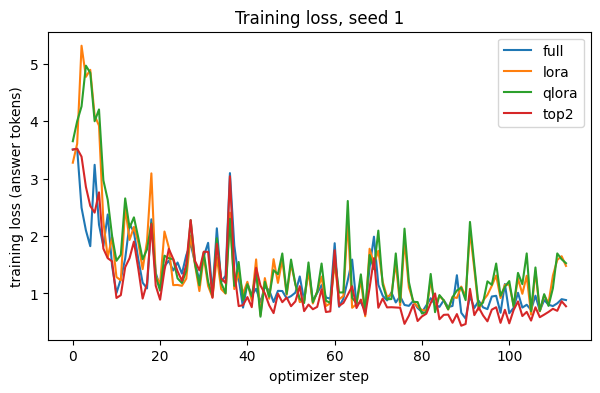

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4))
for r in sorted(load_results(RESULTS), key=lambda r: r["name"]):
    c = r["config"]
    if c["method"] in MAIN and c["seed"] == 1 and not r.get("oom") and not c["n_train"] and "train" in r:
        ax.plot(r["train"]["losses"], label=c["method"])
ax.set_xlabel("optimizer step"); ax.set_ylabel("training loss (answer tokens)"); ax.legend()
ax.set_title("Training loss, seed 1"); plt.show()

## 6. Paper Tables 5 and 6: which matrices, and what rank (after the first draft)

**Rank sweep** (Table 6): LoRA on $W_q, W_v$ with $r \in \{1, 2, 4, 8, 64\}$.
**Module comparison** (Table 5): a similar parameter budget spent on different matrices.
Seed 1 only; add seeds if time allows.

In [ ]:
for r_ in [1, 2, 4, 8, 64]:
    run(RunConfig("lora", rank=r_, alpha=2 * r_, lr=LR["lora"], seed=1, precision=PRECISION), data, RESULTS,
        latency=False)
for targets, r_ in [(("q_proj",), 8), (("v_proj",), 8), (("q_proj", "v_proj"), 4),
                    (("q_proj", "k_proj", "v_proj", "o_proj"), 2)]:
    run(RunConfig("lora", rank=r_, alpha=2 * r_, targets=targets, lr=LR["lora"], seed=1, precision=PRECISION),
        data, RESULTS, latency=False)
summarize(RESULTS).query("method == 'lora'")[["all_strict", "all_lenient", "trainable_params"]].round(3)

[skip] lora_r1_q-v_lr0.0002_s1: result exists
[skip] lora_r2_q-v_lr0.0002_s1: result exists
[skip] lora_r4_q-v_lr0.0002_s1: result exists
[skip] lora_r8_q-v_lr0.0002_s1: result exists
[skip] lora_r64_q-v_lr0.0002_s1: result exists
[skip] lora_r8_q_lr0.0002_s1: result exists
[skip] lora_r8_v_lr0.0002_s1: result exists
[skip] lora_r4_q-v_lr0.0002_s1: result exists
[skip] lora_r2_q-k-v-o_lr0.0002_s1: result exists


all_strict       all_lenient       trainable_params     
                                                                                 mean   std        mean   std             mean  std
config                   method prompt    rank targets                                                                             
lora_r1_q-v_lr0.0002     lora   zero_shot 1    q_proj+v_proj                     0.18   NaN        0.18   NaN          93184.0  NaN
lora_r2_q-k-v-o_lr0.0002 lora   zero_shot 2    q_proj+k_proj+v_proj+o_proj       0.17   NaN        0.17   NaN         372736.0  NaN
lora_r2_q-v_lr0.0002     lora   zero_shot 2    q_proj+v_proj                     0.19   NaN        0.19   NaN         186368.0  NaN
lora_r4_q-v_lr0.0002     lora   zero_shot 4    q_proj+v_proj                     0.19   NaN        0.19   NaN         372736.0  NaN
lora_r64_q-v_lr0.0002    lora   zero_shot 64   q_proj+v_proj                     0.13   NaN        0.13   NaN        5963776.0  NaN
lora_r8_q-v_lr0.0002     lora   zero_shot 8    q_proj+v_proj                     0.16  0.01        0.16  0.01         745472.0  0.0
lora_r8_q_lr0.0002       lora   zero_shot 8    q_proj                            0.19   NaN        0.19   NaN         452608.0  NaN
lora_r8_v_lr0.0002       lora   zero_shot 8    v_proj                            0.17   NaN        0.17   NaN         292864.0  NaN

*Note on alpha:* the paper fixes $\alpha$ to the first $r$ tried and scales the update by $\alpha/r$. The main runs use
$\alpha = 16, r = 8$ (scale 2); the sweep keeps the scale at 2 ($\alpha = 2r$) so that only the rank changes. State this in the report.

## 7. Analysis (no GPU needed)

Everything here reads the saved results on Drive, so it can run on a CPU runtime. The code is in `src/analysis.py`.

**Statistics.** All methods are scored on the same 100 test items, so comparisons are *paired*. For multi-seed
methods each item's correctness is first averaged over seeds. Confidence intervals come from a bootstrap over test
items, and p-values from a sign-flip permutation test on per-item differences. This replaces the per-seed McNemar
tests with one test per comparison, and puts test-set sampling error into every interval.

In [35]:
import matplotlib.pyplot as plt
import pandas as pd
LR = globals().get("LR", {"lora": 2e-4})      # section 4's values, if this is a fresh runtime
FIG_DIR = f"{DRIVE_DIR}/figures"
A = analysis.Results(RESULTS, DATA_DIR)
A.accuracy_table().round(3)

,n_seeds,trainable_params,all,mc,short,stats,mc_rules,mc_history,all_ci_low,all_ci_high
base_zero_shot,1.0,0.0,0.140,0.394,0.030,0.000,0.312,0.471,0.080,0.210
base_few_shot,1.0,0.0,0.170,0.485,0.030,0.000,0.500,0.471,0.100,0.240
lora_r1_q-v_lr0.0002,1.0,93184.0,0.180,0.515,0.030,0.000,0.562,0.471,0.110,0.250
lora_r2_q-v_lr0.0002,1.0,186368.0,0.190,0.485,0.091,0.000,0.500,0.471,0.120,0.270
lora_r8_v_lr0.0002,1.0,292864.0,0.170,0.424,0.091,0.000,0.375,0.471,0.100,0.240
lora_r4_q-v_lr0.0002,1.0,372736.0,0.190,0.485,0.091,0.000,0.500,0.471,0.120,0.270
lora_r2_q-k-v-o_lr0.0002,1.0,372736.0,0.170,0.424,0.091,0.000,0.375,0.471,0.100,0.250
lora_r8_q_lr0.0002,1.0,452608.0,0.190,0.455,0.091,0.029,0.438,0.471,0.120,0.270
lora_r8_q-v_lr0.0002,3.0,745472.0,0.160,0.394,0.091,0.000,0.396,0.392,0.093,0.227
qlora_r8_q-v_lr0.0002,3.0,745472.0,0.153,0.404,0.061,0.000,0.354,0.451,0.093,0.223


### Paired comparisons
`diff` = accuracy of B minus accuracy of A, with a 95% bootstrap CI. Default pairs: every method vs. the few-shot
base model, plus **LoRA vs. full fine-tuning** (the paper's main claim), LoRA vs. QLoRA, and LoRA vs. last-2-layers.

In [36]:
A.comparisons().round(3)

,A,B,acc_a,acc_b,diff,ci_low,ci_high,p
0,base_few_shot,lora_r1_q-v_lr0.0002,0.170,0.180,0.010,-0.060,0.080,1.000
1,base_few_shot,lora_r2_q-v_lr0.0002,0.170,0.190,0.020,-0.060,0.100,0.810
2,base_few_shot,lora_r8_v_lr0.0002,0.170,0.170,0.000,-0.080,0.080,1.000
3,base_few_shot,lora_r4_q-v_lr0.0002,0.170,0.190,0.020,-0.060,0.100,0.808
4,base_few_shot,lora_r2_q-k-v-o_lr0.0002,0.170,0.170,0.000,-0.080,0.080,1.000
5,base_few_shot,lora_r8_q_lr0.0002,0.170,0.190,0.020,-0.060,0.100,0.799
6,base_few_shot,lora_r8_q-v_lr0.0002,0.170,0.160,-0.010,-0.087,0.067,0.869
7,base_few_shot,qlora_r8_q-v_lr0.0002,0.170,0.153,-0.017,-0.083,0.047,0.703
8,base_few_shot,lora_r64_q-v_lr0.0002,0.170,0.130,-0.040,-0.130,0.050,0.501
9,base_few_shot,top2_lr0.0001,0.170,0.140,-0.030,-0.093,0.030,0.416


### Accuracy vs. trainable parameters
The trend slope is the OLS slope of accuracy on $\log_{10}$(trainable parameters) across all trained
configurations, in accuracy points per 10x more parameters. Its CI and p-value come from a bootstrap over test items.

{'slope_per_10x_params': -0.020087559458356986, 'ci_low': -0.038971351123640544, 'ci_high': -0.0017188491242579667, 'p': 0.029, 'n_configs': 11, 'configs': ['lora_r1_q-v_lr0.0002', 'lora_r2_q-v_lr0.0002', 'lora_r8_v_lr0.0002', 'lora_r4_q-v_lr0.0002', 'lora_r2_q-k-v-o_lr0.0002', 'lora_r8_q_lr0.0002', 'lora_r8_q-v_lr0.0002', 'qlora_r8_q-v_lr0.0002', 'lora_r64_q-v_lr0.0002', 'top2_lr0.0001', 'full_lr2e-05']}


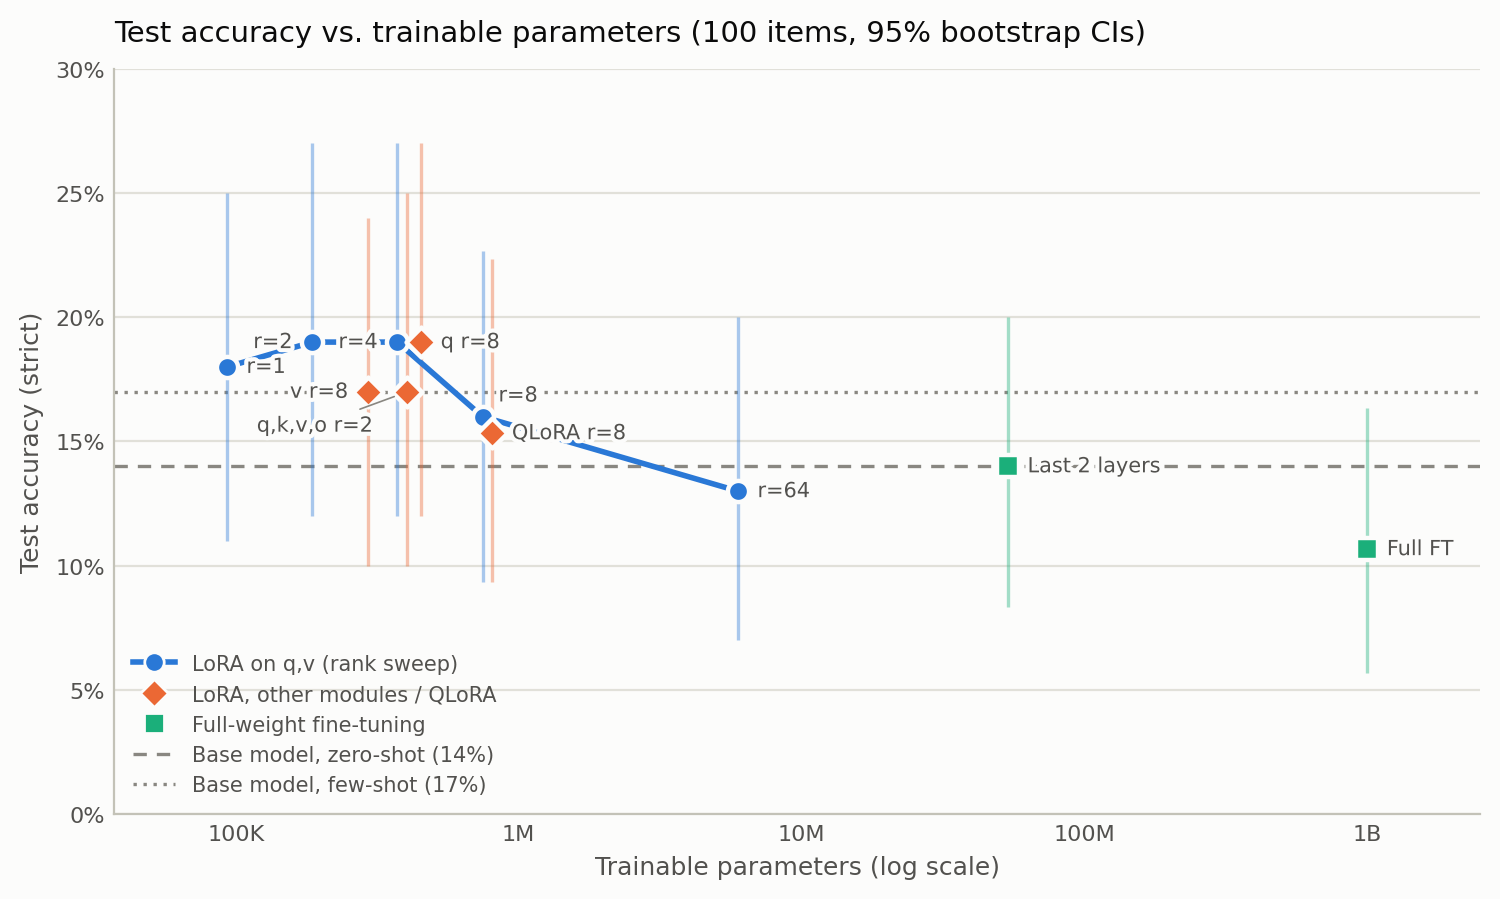

In [37]:
print(A.trend())
A.plot_accuracy_vs_params(f"{FIG_DIR}/accuracy_vs_params.png"); plt.show()

### Extra metrics
**Stats closeness**: exact accuracy on the stats questions is 0 for every method, so this asks how *close* the numbers
are: the share within 1%, 5% and 10% relative error, and the median relative error (seeds pooled).
**MC baselines**: accuracy of answer-blind strategies (chance, always "A", always the longest option). A method that
does no better than "longest answer" on the rules questions has not learned the rules.

In [38]:
display(A.stats_closeness().round(3))
display(A.mc_baselines().round(3))

,within_1pct,within_5pct,within_10pct,median_rel_error,no_number
base_zero_shot,0.000,0.029,0.088,211.595,0.412
base_few_shot,0.000,0.147,0.206,0.204,0.000
lora_r1_q-v_lr0.0002,0.029,0.147,0.206,0.294,0.000
lora_r2_q-v_lr0.0002,0.029,0.088,0.265,0.194,0.000
lora_r8_v_lr0.0002,0.000,0.147,0.294,0.191,0.000
lora_r4_q-v_lr0.0002,0.029,0.088,0.206,0.242,0.000
lora_r2_q-k-v-o_lr0.0002,0.029,0.118,0.235,0.198,0.000
lora_r8_q_lr0.0002,0.029,0.088,0.324,0.186,0.000
lora_r8_q-v_lr0.0002,0.000,0.108,0.275,0.192,0.000
qlora_r8_q-v_lr0.0002,0.000,0.108,0.255,0.198,0.000


,n,chance,always_A,best_single_letter,longest_answer
all MC,33.0,0.25,0.273,0.273,0.303
rules MC,16.0,0.25,0.312,0.375,0.312
history MC,17.0,0.25,0.235,0.353,0.294


### Subspace similarity (paper Section 7.2, Figures 3 and 4)
$\phi(i, j) = \lVert U_i^\top U'_j \rVert_F^2 / \min(i, j)$ compares the top-$i$ directions of one adapter with the
top-$j$ directions of another: 1 means the subspaces overlap completely, 0 means they are orthogonal. For random
subspaces of dimension $d$, $E[\phi(i, j)] = \max(i, j)/d$.

Two versions:
* **Input side (the paper's version).** $U$ = right-singular vectors of $A$. $A$ starts as a *random* matrix, and we
  train for only about 113 steps (the paper trained GPT-3 for far longer), so $A$ may still mostly reflect its
  initialisation. Then $\phi$ is near the random level whether or not the updates share structure.
  `A_norm_vs_init` near 1 means $\lVert A \rVert_F$ is still what it was at initialisation.
* **Output side (added for this short-training setting).** $U$ = left-singular vectors of $\Delta W = BA$, i.e. the
  output directions the update writes into. $B$ starts at **zero**, so every one of these directions was learned.

Each is shown for rank 8 vs. rank 64 (Fig. 3) and rank 8 with seeds 1 and 100 (Fig. 4).

input side: r=8 vs r=64


,module,side,r_a,r_b,d,phi_11,phi_11_all_layers,phi_11_random,phi_1_all,phi_1_all_all_layers,phi_1_all_random,phi_1_all_random_expected,A_norm_vs_init
0,q_proj,input,8,64,1152,0.001,0.003,0.0,0.050,0.062,0.054,0.056,1.012
1,v_proj,input,8,64,1152,0.001,0.035,0.0,0.061,0.095,0.075,0.056,1.021


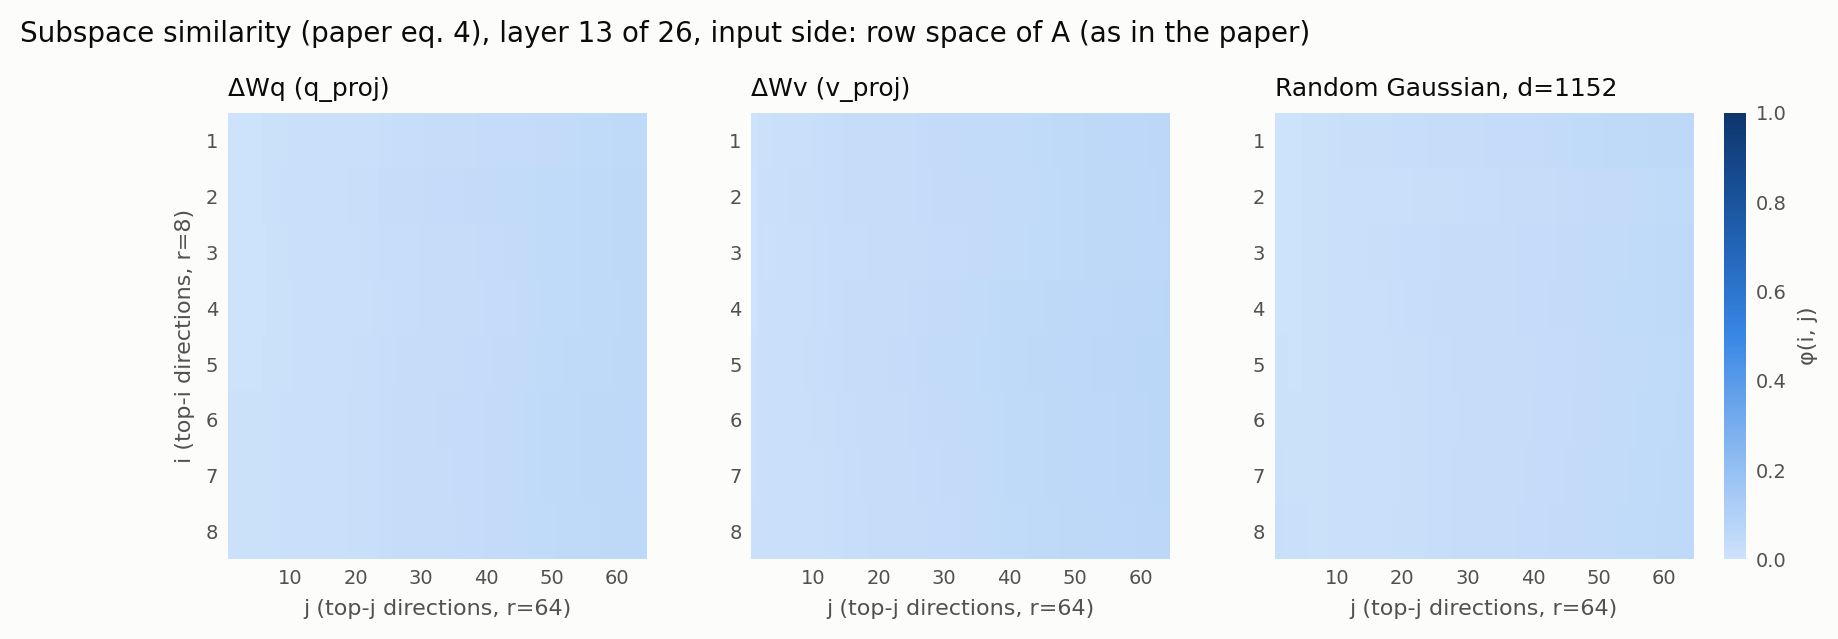

input side: r=8, seed 1 vs r=8, seed 100


,module,side,r_a,r_b,d,phi_11,phi_11_all_layers,phi_11_random,phi_1_all,phi_1_all_all_layers,phi_1_all_random,phi_1_all_random_expected,A_norm_vs_init
0,q_proj,input,8,8,1152,0.001,0.006,0.0,0.009,0.015,0.007,0.007,1.012
1,v_proj,input,8,8,1152,0.033,0.043,0.0,0.043,0.052,0.011,0.007,1.021


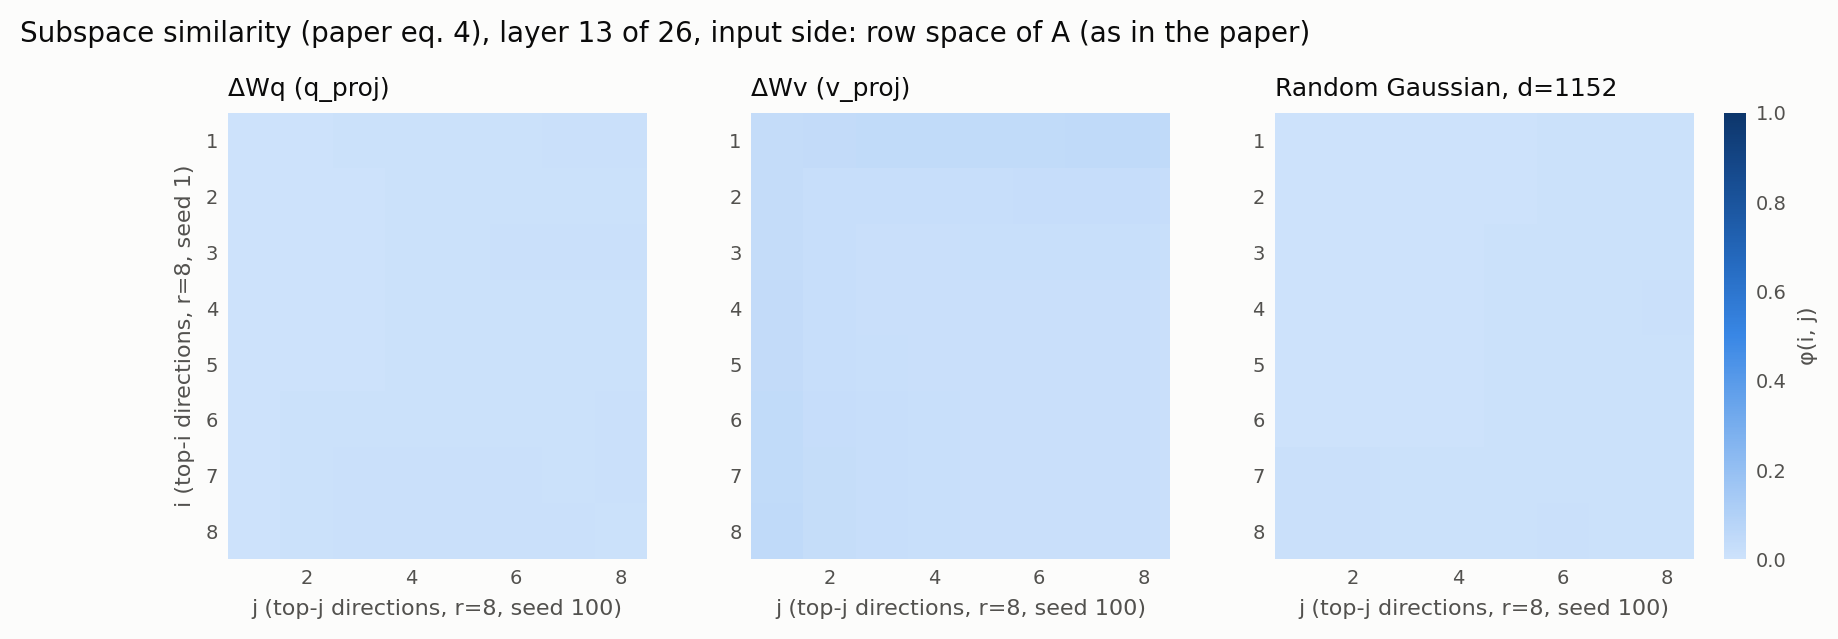

In [39]:
adapters = f"{RESULTS}/adapters"
r8_s1 = RunConfig("lora", lr=LR["lora"], seed=1).name
r64_s1 = RunConfig("lora", rank=64, alpha=128, lr=LR["lora"], seed=1).name
r8_s100 = RunConfig("lora", lr=LR["lora"], seed=100).name
PAIRS = {"r8_vs_r64": (r8_s1, r64_s1, "r=8", "r=64"),
         "r8_seed1_vs_seed100": (r8_s1, r8_s100, "r=8, seed 1", "r=8, seed 100")}

def show_subspace(side):
    for key, (a, b, la, lb) in PAIRS.items():
        sim = analysis.subspace_similarity(f"{adapters}/{a}", f"{adapters}/{b}", side=side)
        print(f"{side} side: {la} vs {lb}")
        display(sim["summary"].round(3))
        analysis.plot_subspace(sim, f"{FIG_DIR}/subspace_{key}_{side}.png", la, lb); plt.show()

show_subspace("input")      # the paper's version

output side: r=8 vs r=64


,module,side,r_a,r_b,d,phi_11,phi_11_all_layers,phi_11_random,phi_1_all,phi_1_all_all_layers,phi_1_all_random,phi_1_all_random_expected,A_norm_vs_init
0,q_proj,output,8,64,1024,0.401,0.320,0.001,0.782,0.715,0.081,0.062,1.012
1,v_proj,output,8,64,256,0.515,0.453,0.005,0.709,0.726,0.302,0.250,1.021


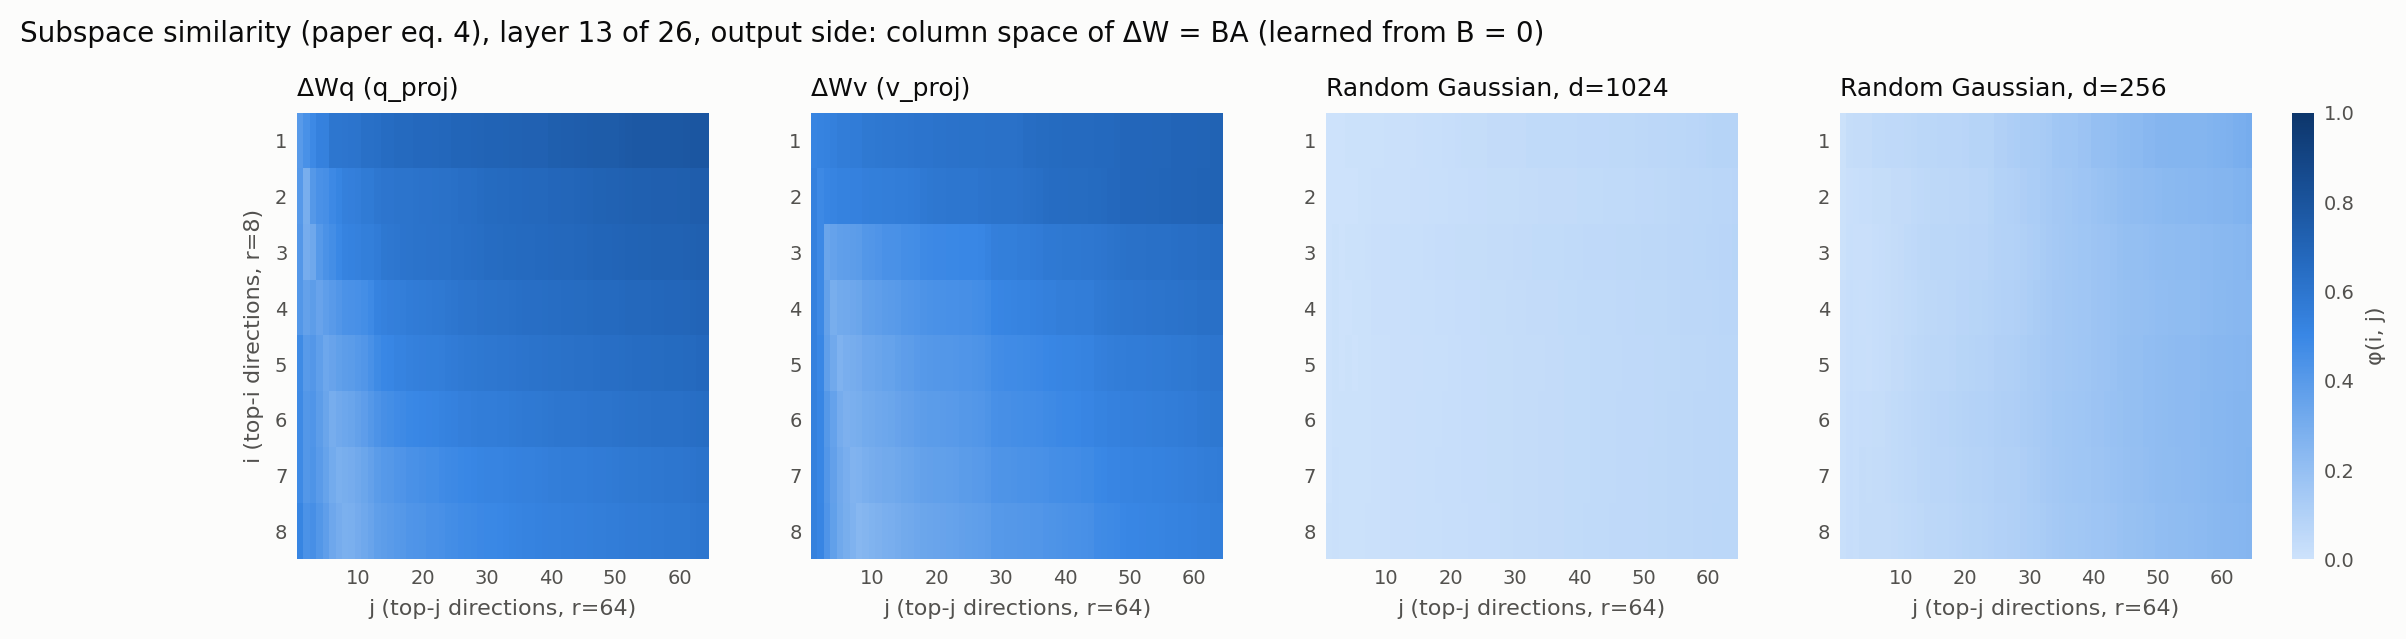

output side: r=8, seed 1 vs r=8, seed 100


,module,side,r_a,r_b,d,phi_11,phi_11_all_layers,phi_11_random,phi_1_all,phi_1_all_all_layers,phi_1_all_random,phi_1_all_random_expected,A_norm_vs_init
0,q_proj,output,8,8,1024,0.641,0.541,0.000,0.691,0.676,0.007,0.008,1.012
1,v_proj,output,8,8,256,0.732,0.659,0.003,0.781,0.744,0.019,0.031,1.021


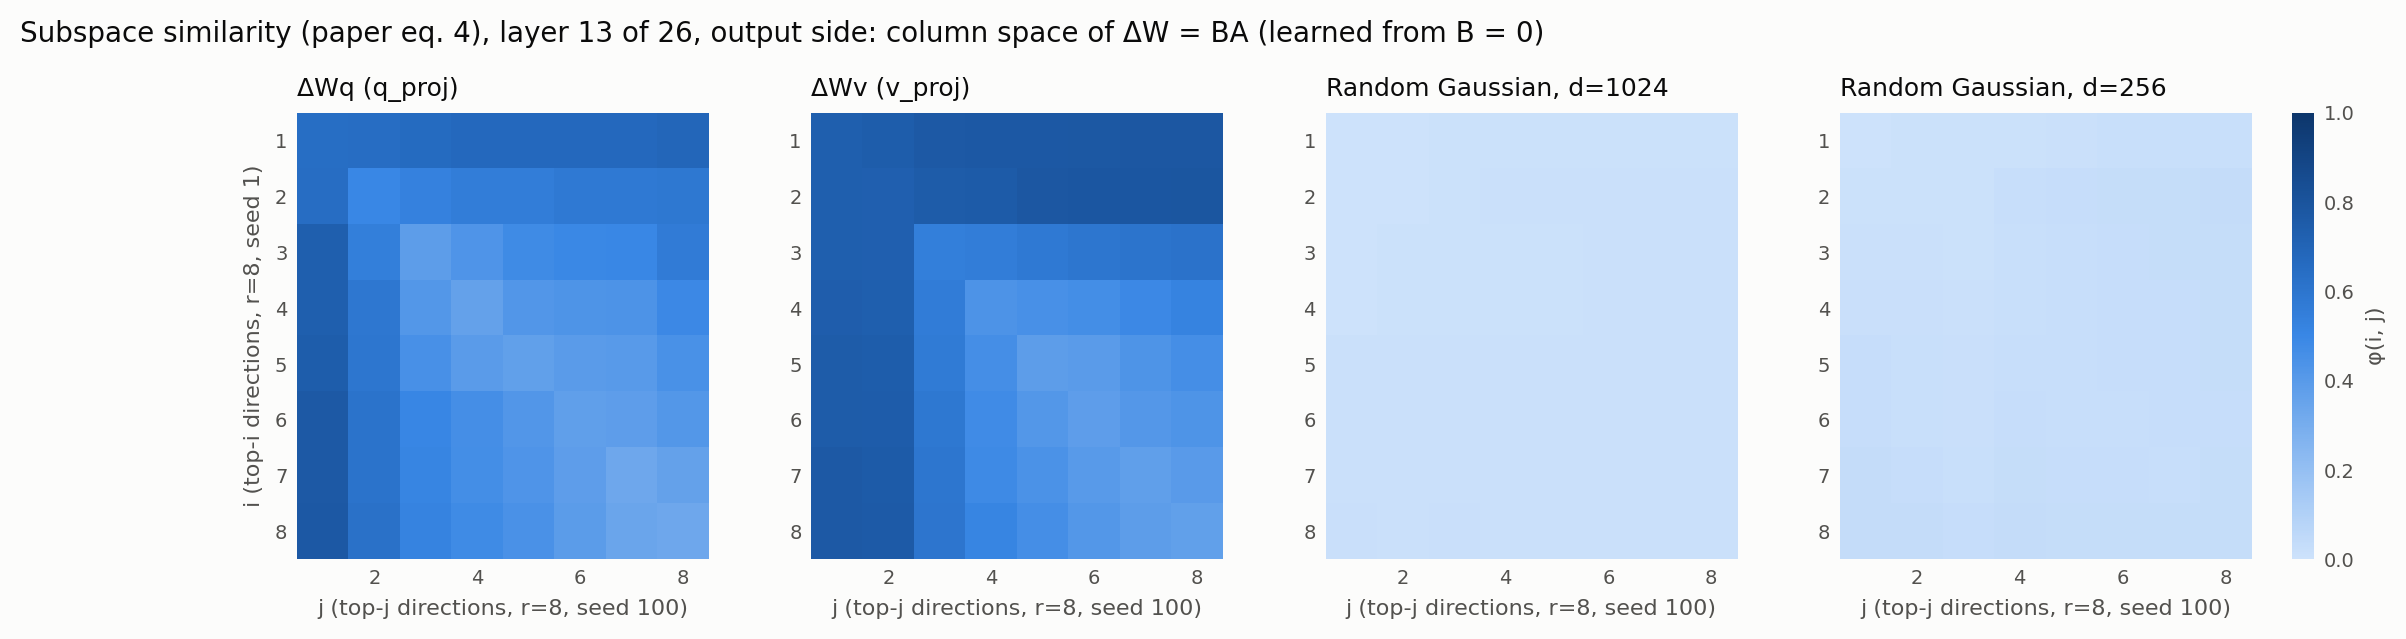

In [40]:
show_subspace("output")     # learned output directions of ΔW = BA

## 8. Optional: memory demo on a free T4

Switch the runtime to **T4**, rerun sections 0 and 1, then run this cell. Full fine-tuning is expected to run out of
memory while LoRA fits, which is the paper's "lowers the hardware barrier" claim. OOMs are saved as results.

In [ ]:
assert "T4" in torch.cuda.get_device_name(0), "switch the runtime to T4 first"
for method in ["full", "lora"]:
    run(RunConfig(method, lr=LR[method], seed=1, precision="fp32", tag="_t4"), data, RESULTS, latency=False)

## 9. Export results to GitHub (run after section 7)

Copies everything the report needs from Drive into `results/colab_L4/` in the repo, then commits and pushes it to
`main`, so teammates can read the numbers without Colab:
* every run file (`runs/*.json`, with predictions), **not** the adapters (too large);
* the figures from section 7;
* report-ready tables (`tables/*.csv`): results summary, accuracy by type, paired comparisons, trend, stats closeness,
  MC baselines, subspace similarity. `results/colab_L4/README.md` explains each file.

**Pushing needs a token** in a Colab secret named `GITHUB_TOKEN`. This repo belongs to another account, and
fine-grained tokens can't be given access to a repo you're only a collaborator on, so use a **classic** token:
GitHub → Settings → Developer settings → Personal access tokens → *Tokens (classic)* → Generate new token, tick only
**`public_repo`** (the repo is public), and set a short expiration. The token is used only for the push and is never
printed or saved in the repo. Revoke it when the project is done.

**No token?** Leave the secret out: the cell downloads `colab_L4_results.zip` instead. Unzip it into
`results/colab_L4/` in your local copy of the repo and commit it from there.

Rerunning replaces the folder, so after new runs (e.g. extra seeds) just run sections 7 and 9 again.

In [ ]:
import importlib, shutil, export_results
importlib.reload(export_results)
LR = globals().get("LR", {"lora": 2e-4})
EXPORT = "results/colab_L4"
PAIRS = {"r8_vs_r64": (RunConfig("lora", lr=LR["lora"], seed=1).name,
                       RunConfig("lora", rank=64, alpha=128, lr=LR["lora"], seed=1).name, "r=8", "r=64"),
         "r8_seed1_vs_seed100": (RunConfig("lora", lr=LR["lora"], seed=1).name,
                                 RunConfig("lora", lr=LR["lora"], seed=100).name, "r=8, seed 1", "r=8, seed 100")}
export_results.export(RESULTS, DATA_DIR, f"{DRIVE_DIR}/figures", f"{REPO_DIR}/{EXPORT}",
                      adapters=f"{RESULTS}/adapters", pairs=PAIRS)

token = secret("GITHUB_TOKEN")
if token:
    export_results.push(REPO_DIR, EXPORT, f"Add Colab results ({gpu})", token=token)
else:
    from google.colab import files
    zip_path = shutil.make_archive("/content/colab_L4_results", "zip", f"{REPO_DIR}/{EXPORT}")
    files.download(zip_path)
    print("No GITHUB_TOKEN secret, so nothing was pushed. Downloaded colab_L4_results.zip instead:\n"
          "unzip it into results/colab_L4/ in the repo and commit it.")